# The Price of Intelligence: AI Model Pricing (2023–2026)

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
warnings.filterwarnings('ignore')

colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
dark, gray, grid = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({
    'figure.figsize': (12, 5), 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': gray, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.titlecolor': dark, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': grid, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': gray, 'ytick.color': gray, 'lines.linewidth': 2, 'legend.frameon': False,
})
usd = mt.FuncFormatter(lambda v, _: f'${v:,.2f}' if v < 1 else f'${v:,.0f}')
tokens = mt.FuncFormatter(lambda v, _: f'{v/1e6:g}M' if v >= 1e6 else f'{v/1e3:g}K')

folder = '/Users/sakshamchauhan/Downloads/Data/'
models = pd.read_csv(folder + 'ai_models_2026.csv', parse_dates=['first_listed_week'])
history = pd.read_csv(folder + 'ai_model_price_history.csv', parse_dates=['week_start'])
print('models:', models.shape, '| history:', history.shape)
models.head()

models: (4403, 31) | history: (167787, 9)


,model_id,model_name,developer,developer_country,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,cached_input_price_per_1m_tokens,batch_input_price_per_1m_tokens,...,supports_web_search,supports_audio_input,supports_audio_output,supports_video_input,supports_response_schema,supports_computer_use,supports_system_messages,deprecation_date,first_listed_week,source_url
0,fireworks_ai/accounts/fireworks/models/llava-y...,llava-yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
1,fireworks_ai/accounts/fireworks/models/yi-34b,yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
2,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-200k-capybara,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
3,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-chat,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
4,fireworks_ai/accounts/fireworks/models/yi-6b,yi-6b,01.AI,China,fireworks_ai,chat,0.2,0.2,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN


In [2]:
print('Total entries    :', len(models))
print('Unique models    :', models['model_name'].str.lower().nunique())
print('Developers       :', models['developer'].nunique())
print('Providers        :', models['provider'].nunique())
models['mode'].value_counts().to_frame('entries')

Total entries    : 4403
Unique models    : 2138
Developers       : 51
Providers        : 133


,entries
mode,
chat,3340
image_generation,405
embedding,148
responses,143
audio_transcription,93
realtime,51
video_generation,45
audio_speech,40
completion,34


In [3]:
chat = models[models['mode'].isin(['chat', 'responses']) & models['input_price_per_1m_tokens'].notna()].copy()
chat[['input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens', 'max_output_tokens']].describe().round(2)

,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens,max_output_tokens
count,3316.00,3316.00,3150.00,3129.00
mean,1.96,8.77,412325.88,141622.09
std,6.09,27.02,536064.57,329115.87
min,0.00,0.00,512.00,512.00
25%,0.18,0.50,128000.00,16384.00
50%,0.60,1.80,200000.00,98304.00
75%,1.96,7.56,1000000.00,131072.00
max,150.00,600.00,10485760.00,10000000.00


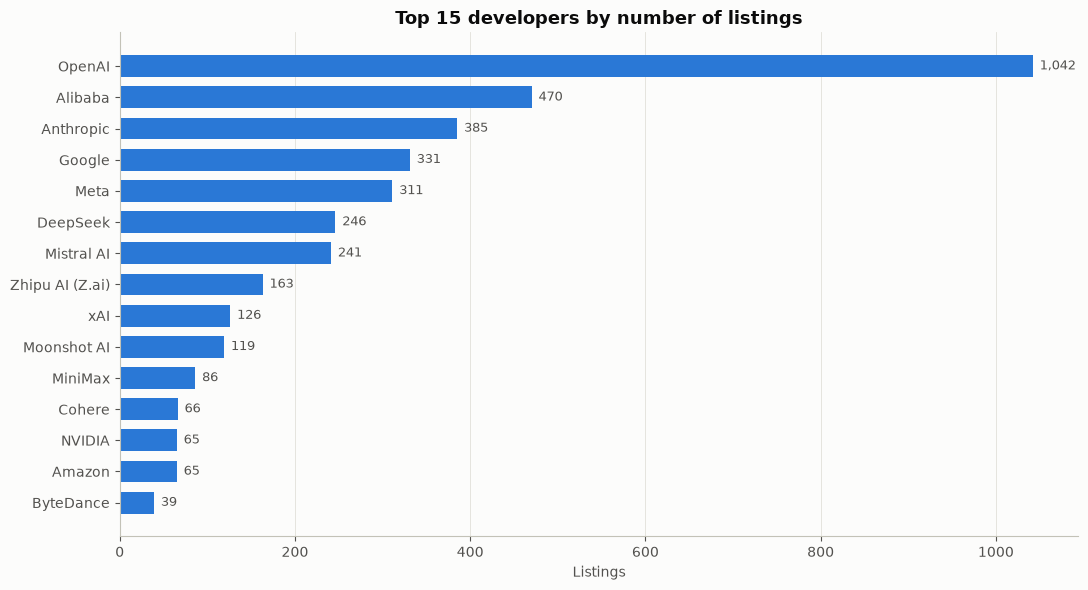

In [4]:
top = models['developer'].value_counts().drop('Other', errors='ignore').head(15).sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top.index, top.values, color=colors[0], height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + 8, i, f'{v:,}', va='center', color=gray, fontsize=9)
ax.set_title('Top 15 developers by number of listings')
ax.set_xlabel('Listings')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

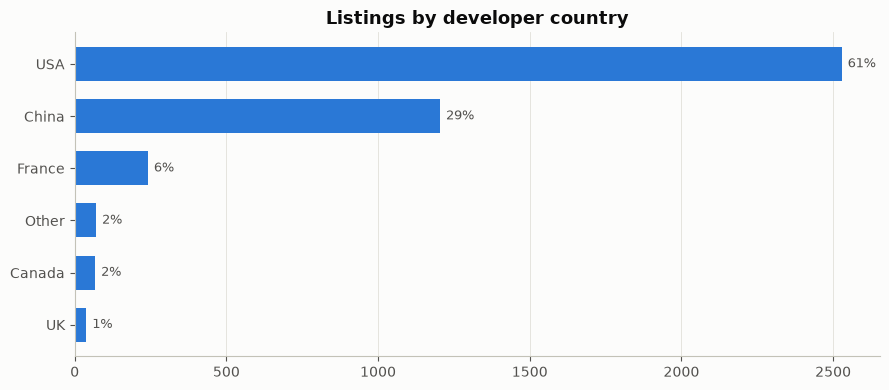

In [5]:
country = models.loc[models['developer_country'] != 'Unknown', 'developer_country'].value_counts()
country = pd.concat([country.head(5), pd.Series({'Other': country.iloc[5:].sum()})]).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(country.index, country.values, color=colors[0], height=0.65)
for i, v in enumerate(country.values):
    ax.text(v + 20, i, f'{v / country.sum():.0%}', va='center', color=gray, fontsize=9)
ax.set_title('Listings by developer country')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

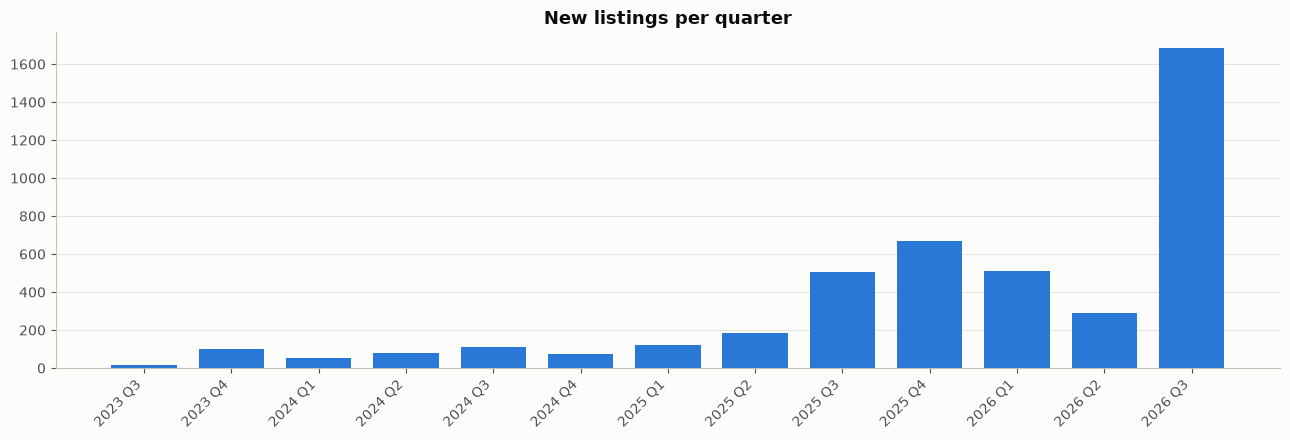

In [6]:
quarterly = models.dropna(subset=['first_listed_week']).set_index('first_listed_week').resample('QE').size()
quarterly.index = [f'{d.year} Q{d.quarter}' for d in quarterly.index]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(quarterly.index, quarterly.values, color=colors[0], width=0.75)
ax.set_title('New listings per quarter')
ax.grid(axis='x', visible=False)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

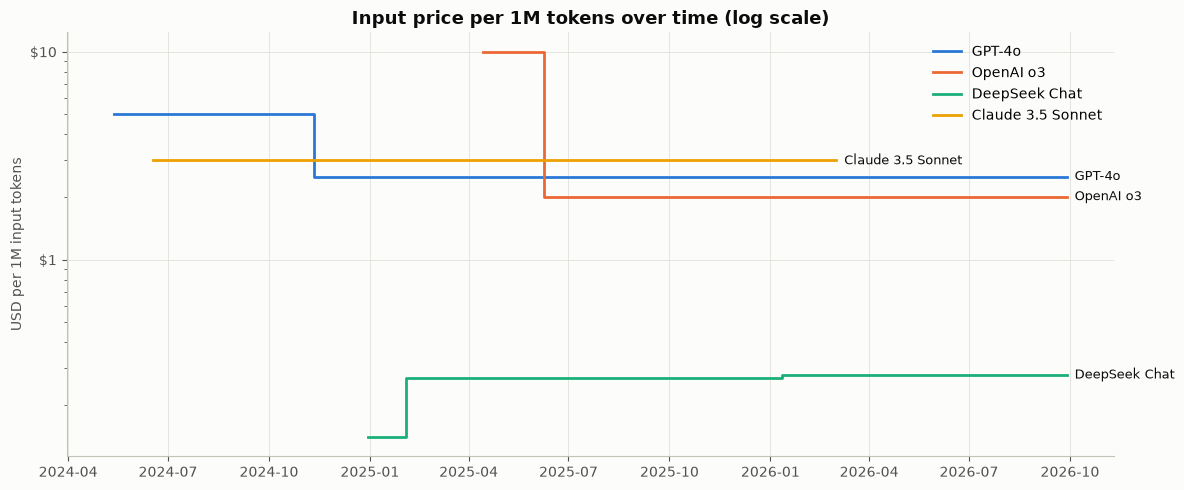

In [7]:
tracked = {'gpt-4o': 'GPT-4o', 'o3': 'OpenAI o3', 'deepseek/deepseek-chat': 'DeepSeek Chat',
           'claude-3-5-sonnet-20240620': 'Claude 3.5 Sonnet'}
fig, ax = plt.subplots(figsize=(12, 5))
for i, (mid, label) in enumerate(tracked.items()):
    d = history[history['model_id'] == mid].sort_values('week_start')
    if d.empty:
        continue
    ax.step(d['week_start'], d['input_price_per_1m_tokens'], where='post', color=colors[i], label=label)
    ax.text(d['week_start'].iloc[-1], d['input_price_per_1m_tokens'].iloc[-1], '  ' + label,
            va='center', color=dark, fontsize=9)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(usd)
ax.set_title('Input price per 1M tokens over time (log scale)')
ax.set_ylabel('USD per 1M input tokens')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [8]:
h = history.dropna(subset=['input_price_per_1m_tokens']).sort_values(['model_id', 'week_start'])
h['prev'] = h.groupby('model_id')['input_price_per_1m_tokens'].shift()
changes = h[(h['prev'] > 0) & (h['input_price_per_1m_tokens'] > 0) & (h['prev'] != h['input_price_per_1m_tokens'])].copy()
changes['change_%'] = (changes['input_price_per_1m_tokens'] / changes['prev'] - 1) * 100
print('Price changes:', len(changes), '| cuts:', (changes['change_%'] < 0).sum(), '| increases:', (changes['change_%'] > 0).sum())

cuts = changes[~changes['model_id'].str.contains('/') & ~changes['model_id'].str.contains('preview|exp|nightly|latest|dolphin')]
cuts = cuts[cuts['change_%'].between(-89.5, -10)].drop_duplicates(['model_name', 'week_start', 'change_%'])
cuts.nsmallest(12, 'change_%')[['week_start', 'model_id', 'developer', 'prev', 'input_price_per_1m_tokens', 'change_%']].round(2)

Price changes: 604 | cuts: 350 | increases: 254


,week_start,model_id,developer,prev,input_price_per_1m_tokens,change_%
69978,2024-11-04,gemini-1.5-flash,Google,0.50,0.08,-85.0
70071,2024-11-04,gemini-1.5-flash-001,Google,0.50,0.08,-85.0
70147,2024-11-04,gemini-1.5-flash-002,Google,0.50,0.08,-85.0
86502,2026-07-27,gpt-5.6-luna,OpenAI,1.00,0.20,-80.0
110443,2025-06-09,o3,OpenAI,10.00,2.00,-80.0
110520,2025-06-09,o3-2025-04-16,OpenAI,10.00,2.00,-80.0
42309,2026-06-15,command-r7b-12-2024,Cohere,0.15,0.04,-75.0
54537,2025-01-27,eu.anthropic.claude-3-5-haiku-20241022-v1:0,Anthropic,1.00,0.25,-75.0
70426,2024-11-04,gemini-1.5-pro,Google,5.00,1.25,-75.0
70519,2024-11-04,gemini-1.5-pro-001,Google,5.00,1.25,-75.0


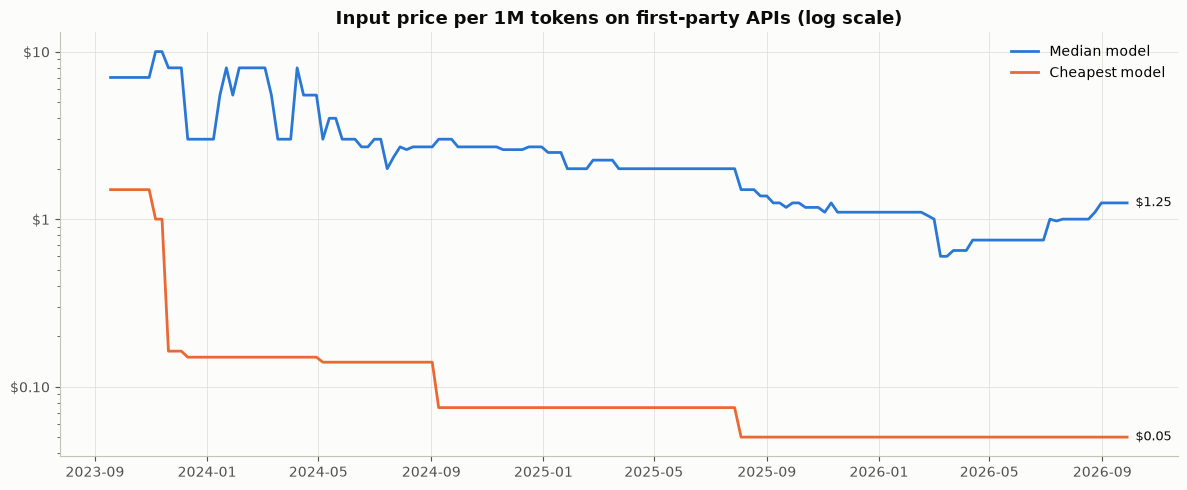

In [9]:
labs = {'openai': 'OpenAI', 'anthropic': 'Anthropic', 'gemini': 'Google', 'xai': 'xAI', 'mistral': 'Mistral AI',
        'deepseek': 'DeepSeek', 'dashscope': 'Alibaba', 'moonshot': 'Moonshot AI'}
lab_hist = history[history['provider'].isin(labs) & (history['mode'] == 'chat') & (history['input_price_per_1m_tokens'] > 0)]
weekly = lab_hist.groupby('week_start')['input_price_per_1m_tokens'].agg(['median', 'min'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly.index, weekly['median'], color=colors[0], label='Median model')
ax.plot(weekly.index, weekly['min'], color=colors[1], label='Cheapest model')
for col in ['median', 'min']:
    ax.annotate(f"${weekly[col].iloc[-1]:.2f}", (weekly.index[-1], weekly[col].iloc[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', color=dark, fontsize=9)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(usd)
ax.set_title('Input price per 1M tokens on first-party APIs (log scale)')
ax.legend()
plt.tight_layout()
plt.show()

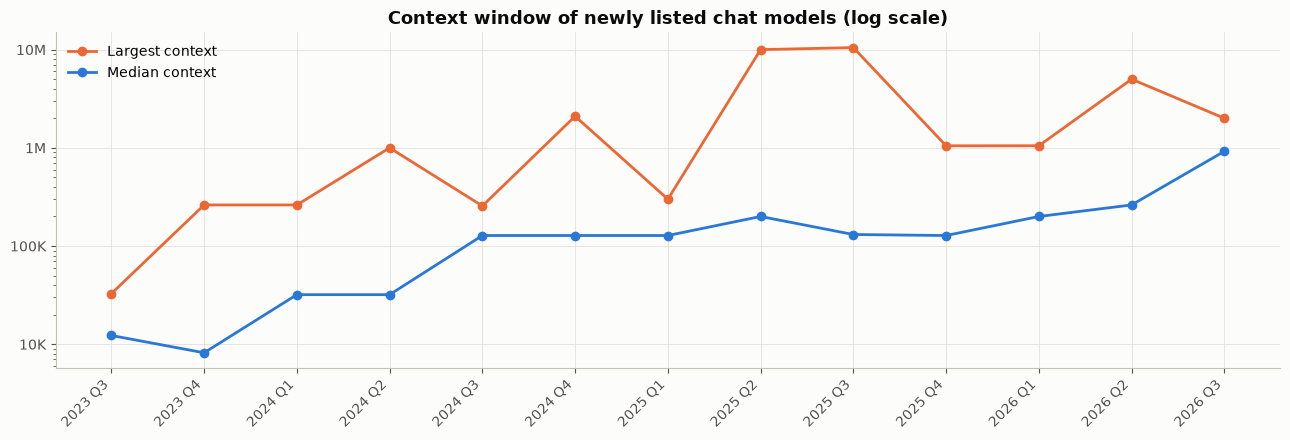

In [10]:
ctx = chat.dropna(subset=['first_listed_week', 'max_input_tokens'])
ctx = ctx.set_index('first_listed_week').resample('QE')['max_input_tokens'].agg(['median', 'max'])
ctx.index = [f'{d.year} Q{d.quarter}' for d in ctx.index]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(ctx.index, ctx['max'], marker='o', color=colors[1], label='Largest context')
ax.plot(ctx.index, ctx['median'], marker='o', color=colors[0], label='Median context')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(tokens)
ax.set_title('Context window of newly listed chat models (log scale)')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

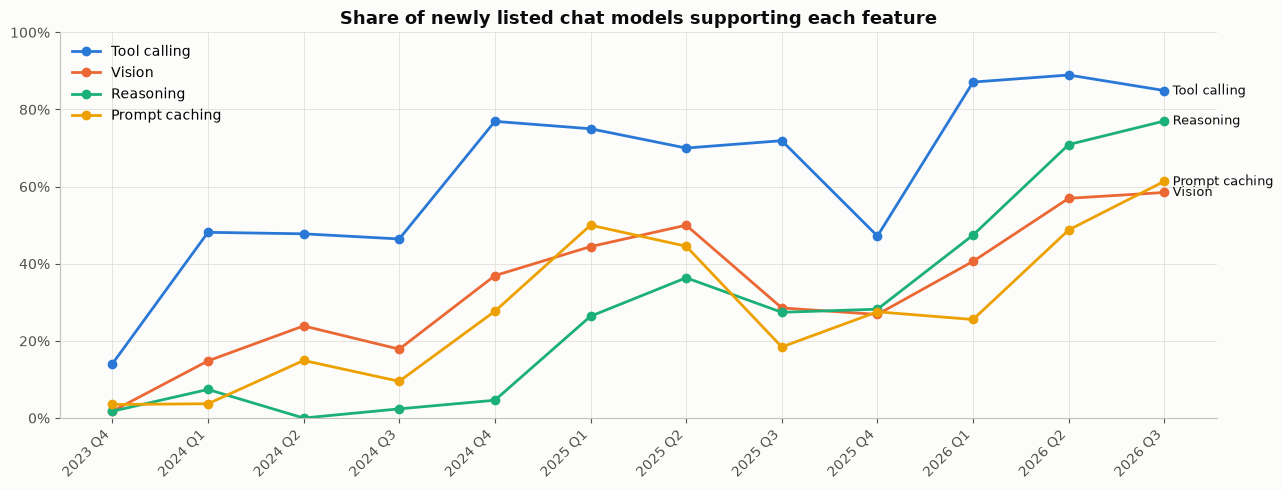

In [11]:
new = chat.dropna(subset=['first_listed_week']).set_index('first_listed_week')
features = {'supports_function_calling': 'Tool calling', 'supports_vision': 'Vision',
            'supports_reasoning': 'Reasoning', 'supports_prompt_caching': 'Prompt caching'}
share = new[list(features)].resample('QE').mean() * 100
share = share[new.resample('QE').size() >= 20]
share.index = [f'{d.year} Q{d.quarter}' for d in share.index]

fig, ax = plt.subplots(figsize=(13, 5))
for i, (col, label) in enumerate(features.items()):
    ax.plot(share.index, share[col], marker='o', color=colors[i], label=label)
    ax.annotate(label, (len(share) - 1, share[col].iloc[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', color=dark, fontsize=9)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mt.PercentFormatter())
ax.set_title('Share of newly listed chat models supporting each feature')
ax.legend(loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

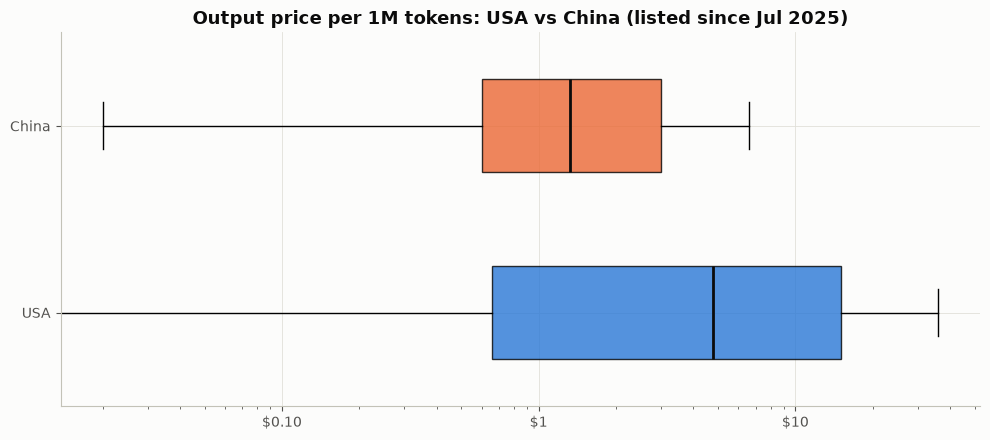

,input_price_per_1m_tokens,output_price_per_1m_tokens
developer_country,,
China,0.40,1.32
USA,1.25,4.76


In [12]:
us_cn = chat[chat['developer_country'].isin(['USA', 'China']) & (chat['input_price_per_1m_tokens'] > 0)]
us_cn = us_cn[us_cn['first_listed_week'] >= '2025-07-01']

fig, ax = plt.subplots(figsize=(10, 4.5))
data = [us_cn.loc[us_cn['developer_country'] == c, 'output_price_per_1m_tokens'].dropna() for c in ['USA', 'China']]
box = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                 medianprops=dict(color=dark, linewidth=2))
ax.set_yticklabels(['USA', 'China'])
for patch, c in zip(box['boxes'], colors[:2]):
    patch.set_facecolor(c)
    patch.set_alpha(0.8)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(usd)
ax.set_title('Output price per 1M tokens: USA vs China (listed since Jul 2025)')
plt.tight_layout()
plt.show()

us_cn.groupby('developer_country')[['input_price_per_1m_tokens', 'output_price_per_1m_tokens']].median().round(2)

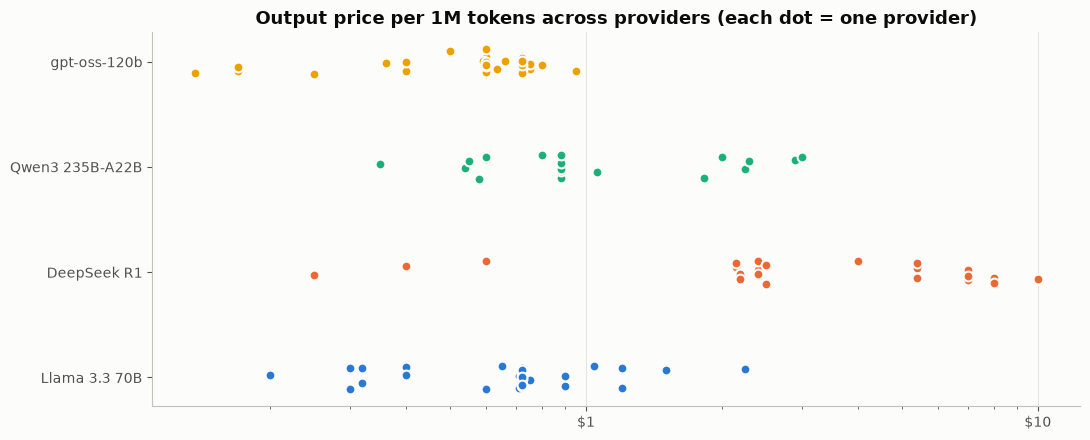

,count,min,median,max,max_vs_min
model,,,,,
DeepSeek R1,22,0.25,2.50,10.00,40.0
Llama 3.3 70B,30,0.20,0.72,2.25,11.3
Qwen3 235B-A22B,21,0.35,0.88,3.00,8.6
gpt-oss-120b,34,0.14,0.60,0.95,7.0


In [13]:
families = {'Llama 3.3 70B': r'llama.?(3\.3|3-3|v3p3|3p3).?70b',
            'DeepSeek R1': r'(^|/)deepseek-r1(-0528)?(-maas|-v1:0)?$',
            'Qwen3 235B-A22B': r'qwen3-235b-a22b',
            'gpt-oss-120b': r'gpt-oss-120b'}
rows = []
for name, pattern in families.items():
    m = chat[chat['model_id'].str.lower().str.contains(pattern) & (chat['output_price_per_1m_tokens'] > 0)]
    for _, r in m.iterrows():
        rows.append((name, r['provider'], r['output_price_per_1m_tokens']))
spread = pd.DataFrame(rows, columns=['model', 'provider', 'price'])

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, name in enumerate(families):
    p = spread.loc[spread['model'] == name, 'price']
    ax.scatter(p, np.full(len(p), i) + np.random.uniform(-0.12, 0.12, len(p)), s=50, color=colors[i],
               edgecolor='#fcfcfb', linewidth=1.5, zorder=3)
ax.set_yticks(range(len(families)))
ax.set_yticklabels(list(families))
ax.grid(axis='y', visible=False)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(usd)
ax.set_title('Output price per 1M tokens across providers (each dot = one provider)')
plt.tight_layout()
plt.show()

spread.groupby('model')['price'].agg(['count', 'min', 'median', 'max']).assign(
    max_vs_min=lambda d: (d['max'] / d['min']).round(1)).round(2)

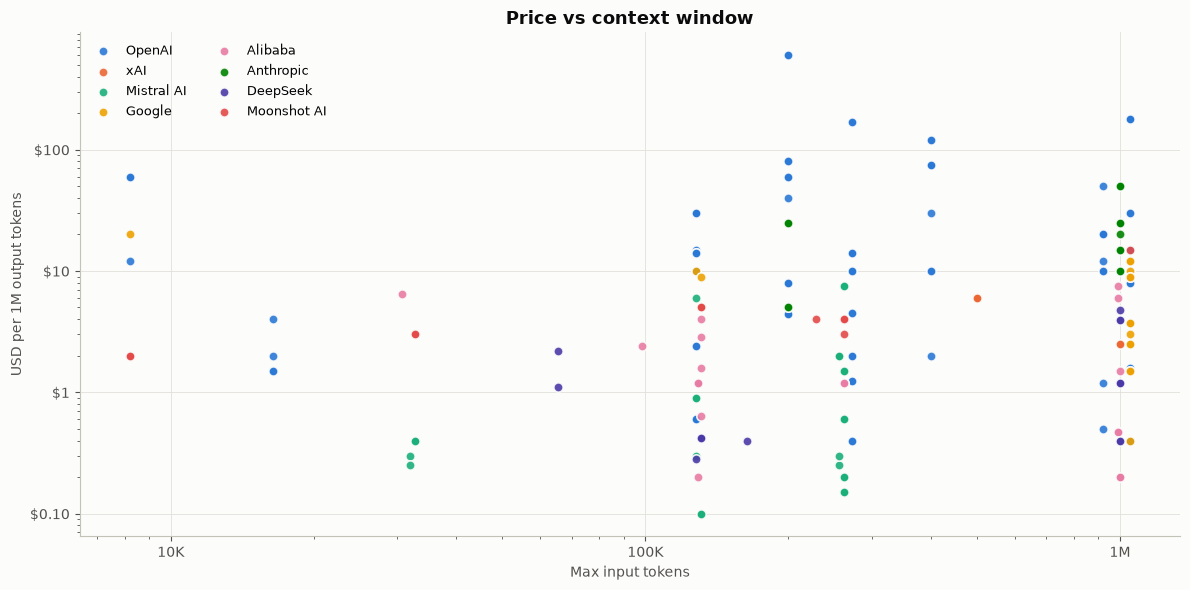

In [14]:
fp = chat[chat['provider'].isin(labs) & (chat['output_price_per_1m_tokens'] > 0)].dropna(subset=['max_input_tokens'])
top_devs = fp['developer'].value_counts().index[:8]

fig, ax = plt.subplots(figsize=(12, 6))
for i, dev in enumerate(top_devs):
    d = fp[fp['developer'] == dev]
    ax.scatter(d['max_input_tokens'], d['output_price_per_1m_tokens'], s=45, color=colors[i], label=dev,
               edgecolor='#fcfcfb', linewidth=1.2, alpha=0.9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(usd)
ax.xaxis.set_major_formatter(tokens)
ax.set_xlabel('Max input tokens')
ax.set_ylabel('USD per 1M output tokens')
ax.set_title('Price vs context window')
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [15]:
cols = ['model_id', 'developer', 'input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']
paid = fp[fp['input_price_per_1m_tokens'] > 0]
print('Most expensive')
display(paid.nlargest(8, 'output_price_per_1m_tokens')[cols])
print('Cheapest')
display(paid.nsmallest(8, 'output_price_per_1m_tokens')[cols])

Most expensive


,model_id,developer,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
3383,o1-pro,OpenAI,150.0,600.0,200000.0
3385,o1-pro-2025-03-19,OpenAI,150.0,600.0,200000.0
3027,gpt-5.4-pro,OpenAI,30.0,180.0,1050000.0
3032,gpt-5.4-pro-2026-03-05,OpenAI,30.0,180.0,1050000.0
3055,gpt-5.5-pro,OpenAI,30.0,180.0,1050000.0
3059,gpt-5.5-pro-2026-04-23,OpenAI,30.0,180.0,1050000.0
2961,gpt-5.2-pro,OpenAI,21.0,168.0,272000.0
2965,gpt-5.2-pro-2025-12-11,OpenAI,21.0,168.0,272000.0


Cheapest


,model_id,developer,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
2252,mistral/ministral-3-3b-2512,Mistral AI,0.10,0.10,131072.0
2258,mistral/ministral-3b-2512,Mistral AI,0.10,0.10,131072.0
2260,mistral/ministral-3b-latest,Mistral AI,0.10,0.10,131072.0
2254,mistral/ministral-3-8b-2512,Mistral AI,0.15,0.15,262144.0
2262,mistral/ministral-8b-2512,Mistral AI,0.15,0.15,262144.0
2265,mistral/ministral-8b-latest,Mistral AI,0.15,0.15,262144.0
195,dashscope/qwen-turbo,Alibaba,0.05,0.20,129024.0
198,dashscope/qwen-turbo-2024-11-01,Alibaba,0.05,0.20,1000000.0
